In [1]:
import pandas as pd
import numpy as np

# Fixed path: Notice there are no double quotes inside the path string
file_path = r'E:\data analyst\pharmaceutical-sales-analysis\Data\salesdaily.csv'

# Load the dataset
df = pd.read_csv(file_path)

# Look at the first 5 rows of data
df.head()


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [2]:
# Check total rows, columns, and data types
print("--- Data Summary Info ---")
df.info()

# Check for any missing (null) values in your columns
print("\n--- Missing Values Count ---")
print(df.isnull().sum())


--- Data Summary Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   object 
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   object 
dtypes: float64(8), int64(3), object(2)
memory usage: 214.0+ KB

--- Missing Values Count ---
datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R0

In [3]:
# Create a list of all drug classification columns
drug_columns = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

# Calculate total sales across all drug types for each row
df['Total_Sales'] = df[drug_columns].sum(axis=1)

# Group the data by day of the week and look at the average sales volume
weekly_sales = df.groupby('Weekday Name')['Total_Sales'].mean().sort_values(ascending=False)
print("--- Average Sales Volume by Day of the Week ---")
print(weekly_sales)


--- Average Sales Volume by Day of the Week ---
Weekday Name
Saturday     65.673071
Sunday       61.134343
Monday       60.607364
Friday       60.247480
Tuesday      60.017432
Wednesday    59.238425
Thursday     57.184018
Name: Total_Sales, dtype: float64


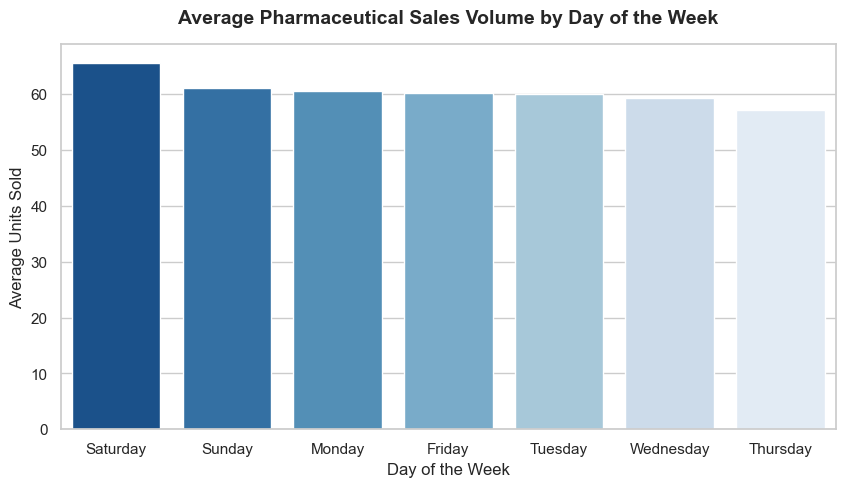

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reset index to make 'Weekday Name' a column for plotting
weekly_sales_df = weekly_sales.reset_index()

# Set up the visual look of the chart
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Create the bar chart
sns.barplot(x='Weekday Name', y='Total_Sales', data=weekly_sales_df, palette='Blues_r')

# Add titles and labels to make it professional
plt.title('Average Pharmaceutical Sales Volume by Day of the Week', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Average Units Sold', fontsize=12)

# Display the chart
plt.show()
